# Benchmark AlphaFold3 against sequence models

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
sequences_100_unbalanced = pd.read_csv('../data/interim/sequences_sample_100_unbalanced.csv', index_col='index')
sequences_100_unbalanced.index = sequences_100_unbalanced.index.astype(str)

In [3]:
confidences_100_unbalanced = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_100_unbalanced.csv')
confidences_100_unbalanced['name'] = confidences_100_unbalanced['name'].astype(str)

confidences_100_unbalanced = confidences_100_unbalanced.loc[
    confidences_100_unbalanced.groupby('name')['ranking_score'].idxmax()
]

In [4]:
confidences_100_unbalanced = confidences_100_unbalanced.merge(
    sequences_100_unbalanced, how='left', left_on='name', right_index=True
)

In [5]:
tcr_struct_map_predictions = pd.read_csv('../data/external/TCRStructMap_predictions_on_sequences_pMHC_split.csv')
tcr_struct_map_predictions['index'] = tcr_struct_map_predictions['index'].astype(str)

In [6]:
tcr_struct_map_predictions_100_unbalanced = tcr_struct_map_predictions.merge(
    sequences_100_unbalanced, how='right', left_on='index', right_index=True
).query('sub_model_number == fold')
tcr_struct_map_predictions_100_unbalanced = tcr_struct_map_predictions_100_unbalanced.set_index('index')

In [7]:
nettcr_predictions = pd.read_csv('../data/external/NetTCR_predictions_on_sequences_pMHC_split.csv')
nettcr_predictions['index'] = nettcr_predictions['index'].astype(str)

In [8]:
nettcr_predictions_100_unbalanced = nettcr_predictions.merge(
    sequences_100_unbalanced, how='right', left_on='index', right_index=True
).query('sub_model_number == fold')
nettcr_predictions_100_unbalanced = nettcr_predictions_100_unbalanced.set_index('index')

In [9]:
def calculate_performance(predictions: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = roc_auc_score(labels, predictions)
    roc_auc01 = roc_auc_score(labels, predictions, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, predictions)
    pr_auc = auc(recall, precision)

    return {'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc}


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [10]:
NUM_SAMPLES = 20
SAMPLE_SIZE = 50

rng = np.random.default_rng(123)

boot_strap_scores = {
    'sample_num': [],
    'model': [],
    'roc_auc': [],
    'roc_auc_01': [],
    'pr_auc': [],
}
for sample_num in range(NUM_SAMPLES):
    indices = sequences_100_unbalanced.sample(SAMPLE_SIZE, random_state=rng).index

    # AlphaFold3
    boot_strap_scores['sample_num'].append(sample_num)
    boot_strap_scores['model'].append('AlphaFold3')

    scores = calculate_performance(
        confidences_100_unbalanced[confidences_100_unbalanced['name'].isin(indices)]['cdr_pmhc_pae_score'],
        confidences_100_unbalanced[confidences_100_unbalanced['name'].isin(indices)]['label'],
    )
    for name, score in scores.items():
        boot_strap_scores[name].append(1 - score)

    # NetTCR
    boot_strap_scores['sample_num'].append(sample_num)
    boot_strap_scores['model'].append('NetTCR')

    scores = calculate_performance(
        nettcr_predictions_100_unbalanced.loc[indices]['prediction'],
        nettcr_predictions_100_unbalanced.loc[indices]['label'],
    )
    for name, score in scores.items():
        boot_strap_scores[name].append(score)

    # TCRStructMap
    boot_strap_scores['sample_num'].append(sample_num)
    boot_strap_scores['model'].append('TCRStructMap')

    scores = calculate_performance(
        tcr_struct_map_predictions_100_unbalanced.loc[indices]['prediction'],
        tcr_struct_map_predictions_100_unbalanced.loc[indices]['label'],
    )
    for name, score in scores.items():
        boot_strap_scores[name].append(score)

boot_strap_scores = pd.DataFrame(boot_strap_scores)

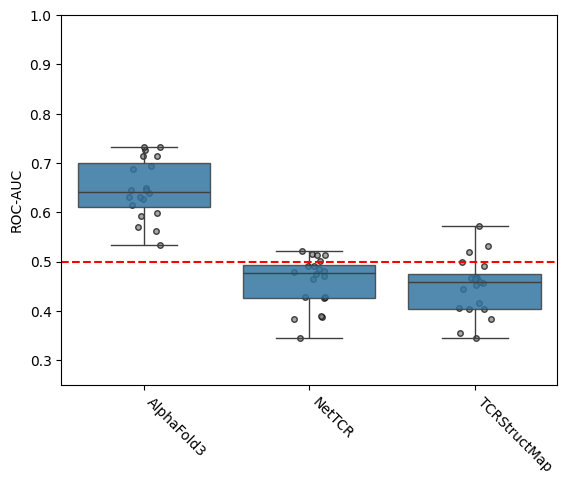

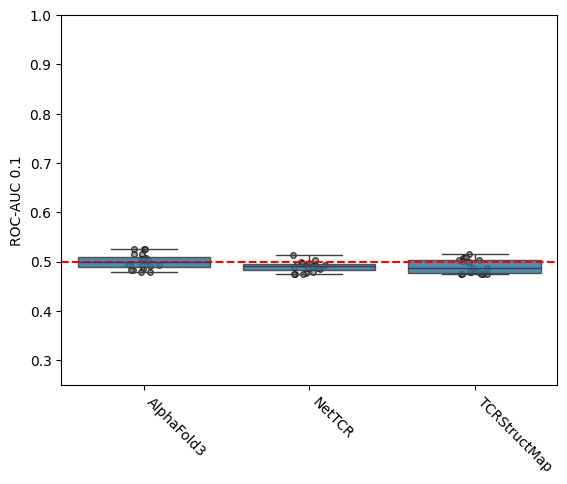

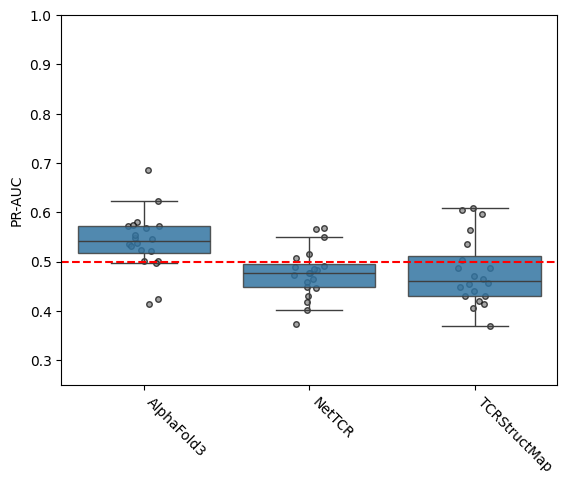

In [11]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    ax = sns.stripplot(
        boot_strap_scores,
        x='model',
        y=metric_name,
        color='grey',
        zorder=1,
        marker='o',
        size=4,
        edgecolor='black',
        linewidth=1,
        alpha=0.70,
    )

    sns.boxplot(boot_strap_scores, x='model', y=metric_name, boxprops={'alpha': 0.85}, showfliers=False)

    ax.axhline(0.5, color='r', linestyle='dashed')

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(ax.get_xticklabels(), rotation=-45, horizontalalignment='left')

    ax.set_xlabel('')
    ax.set_ylim(0.25, 1.0)

    ax.set_ylabel(format_metric_name(metric_name))

    plt.savefig(
        f'../report/figures/alphafold3_sequence_models_specificity_bootstrap_{metric_name}.svg', bbox_inches='tight'
    )
    plt.show()

In [12]:
boot_strap_scores_agg = boot_strap_scores.groupby('model').agg(
    {'roc_auc': ['mean', 'std', 'count'], 'roc_auc_01': ['mean', 'std', 'count'], 'pr_auc': ['mean', 'std', 'count']}
)

std_df = boot_strap_scores_agg.xs('std', axis=1, level=1)
count_df = boot_strap_scores_agg.xs('count', axis=1, level=1)

stderr_df = std_df / np.sqrt(count_df)
stderr_df.columns = pd.MultiIndex.from_product([stderr_df.columns, ['stderr']])

boot_strap_scores_agg = pd.concat([boot_strap_scores_agg, stderr_df], axis=1).sort_index(axis=1)
boot_strap_scores_agg = boot_strap_scores_agg.loc[:, boot_strap_scores_agg.columns.get_level_values(1) != 'count']

boot_strap_scores_agg_means = boot_strap_scores_agg.xs('mean', axis=1, level=1)
boot_strap_scores_agg_stderrs = boot_strap_scores_agg.xs('stderr', axis=1, level=1)

boot_strap_scores_agg = boot_strap_scores_agg_means.combine(
    boot_strap_scores_agg_stderrs, lambda mean, se: mean.map('{:.2f}'.format) + ' ± ' + se.map('{:.2e}'.format)
)

max_mask = boot_strap_scores_agg_means.eq(boot_strap_scores_agg_means.max())

boot_strap_scores_agg.index.name = None

boot_strap_scores_agg = boot_strap_scores_agg[['roc_auc', 'roc_auc_01', 'pr_auc']]
max_mask = max_mask[['roc_auc', 'roc_auc_01', 'pr_auc']]

boot_strap_scores_agg.columns = [format_metric_name(col_name) for col_name in boot_strap_scores_agg.columns]
max_mask.columns = [format_metric_name(col_name) for col_name in max_mask.columns]

# Write to Latex Table
df_tex = boot_strap_scores_agg.copy()

for col in df_tex.columns:
    mask_col = max_mask[col]
    df_tex.loc[mask_col, col] = df_tex.loc[mask_col, col].map(lambda score: r'\textbf{' + score + '}')
    df_tex[col] = df_tex[col].map(lambda score: r'\footnotesize{' + score + '}')


df_tex = df_tex.rename(columns=lambda column_name: r'\small{\textbf{' + column_name + r'}}')
df_tex.index = [r'\small{\textbf{' + idx + r'}}' for idx in df_tex.index]

latex_tabular = df_tex.to_latex(escape=False, index=True, column_format='r' * (len(df_tex.columns) + 1))

with open('../report/alphafold3_sequence_models_specificity_bootstrap.tex', 'w') as fh:
    fh.write(latex_tabular)


# Preview in notebook
def _bold_max_row(row: pd.Series) -> list[str]:
    idx = row.name  # row index label
    return ['font-weight: bold' if max_mask.loc[idx, col] else '' for col in row.index]


styled = boot_strap_scores_agg.style.apply(_bold_max_row, axis=1)

styled

,ROC-AUC,ROC-AUC 0.1,PR-AUC
AlphaFold3,0.65 ± 1.33e-02,0.50 ± 3.51e-03,0.54 ± 1.35e-02
NetTCR,0.46 ± 1.15e-02,0.49 ± 2.41e-03,0.48 ± 1.14e-02
TCRStructMap,0.45 ± 1.30e-02,0.49 ± 3.27e-03,0.48 ± 1.55e-02


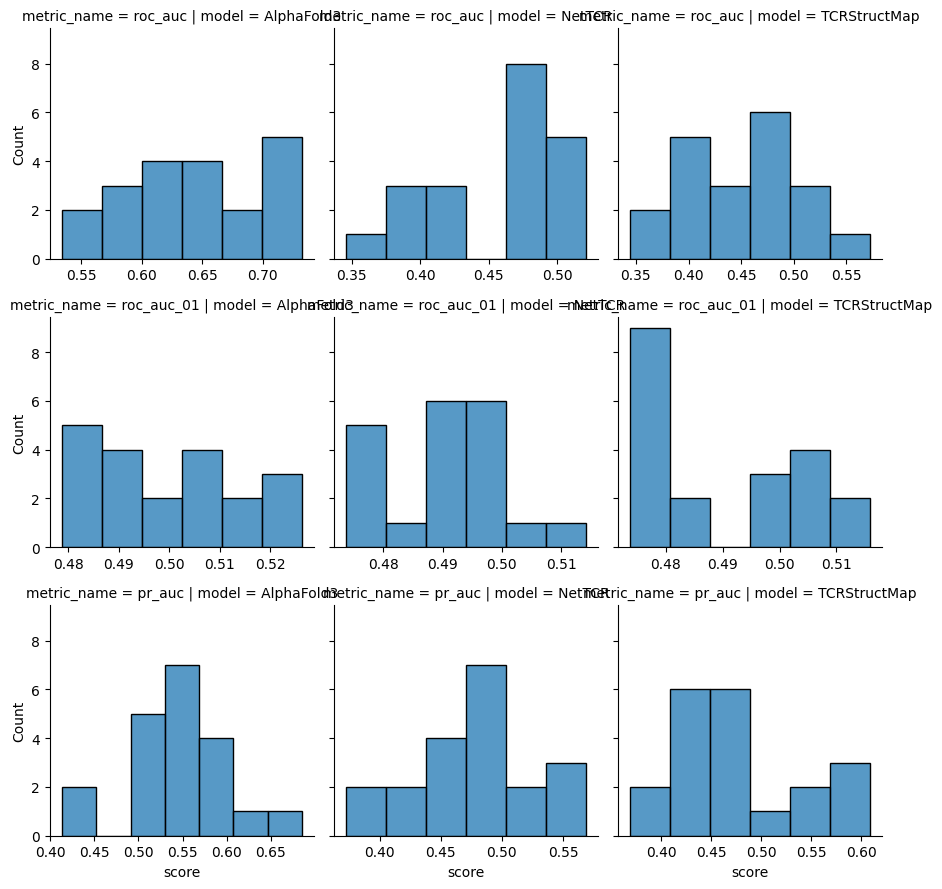

In [13]:
sns.FacetGrid(
    boot_strap_scores.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [14]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.rm_anova(data, dv=metric_name, within='model', subject='sample_num')

    groups = list(data.groupby('model', dropna=False)[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_rel(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [15]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    overall, post_hoc = statistics_normal(boot_strap_scores, metric_name)

    ipy_display.display(overall)
    ipy_display.display(post_hoc)
    print()

ROC-AUC


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,model,2,38,86.976674,6.566335e-15,0.731901,0.573872


,group1,group2,stat,p_val,signficant
0,AlphaFold3,NetTCR,10.538120,2.247602e-09,True
1,AlphaFold3,TCRStructMap,9.015343,2.719696e-08,True
2,NetTCR,TCRStructMap,1.233643,2.323796e-01,False



ROC-AUC 0.1


/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/pingouin/distribution.py:1004: RuntimeWarning: divide by zero encountered in scalar divide
  W = np.prod(eig) / (eig.sum() / d) ** d


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,model,2,38,3.509605,0.039933,0.114351,0.956672


,group1,group2,stat,p_val,signficant
0,AlphaFold3,NetTCR,2.212537,0.039372,False
1,AlphaFold3,TCRStructMap,2.147360,0.044881,False
2,NetTCR,TCRStructMap,-0.165533,0.870273,False



PR-AUC


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,model,2,38,6.2066,0.004651,0.201642,0.57534


,group1,group2,stat,p_val,signficant
0,AlphaFold3,NetTCR,2.873429,0.009730,True
1,AlphaFold3,TCRStructMap,2.321678,0.031518,False
2,NetTCR,TCRStructMap,-0.378493,0.709260,False
